### COMPARATIVE ANALYSIS OF IMPORT SOURCING AND MARKET CONCENTRATION FOR PETROLEUM PRODUCTS IN NIGERIA

#### This report provides a rigorous analytical evaluation of Nigeria's petroleum import market across global and intra-African trade corridors for the 2025–2026 period. 

#### By analysing import values, percentage market shares, Herfindahl-Hirschman Index (HHI) concentration risks, and Pareto distributions, this documentation establishes a robust foundation for assessing supply chain vulnerabilities and long-term regional diversification goals under frameworks like the African Continental Free Trade Area 

In [3]:
import sys
!{sys.executable} -m pip install openpyxl


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
!python.exe -m pip install --upgrade pip

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------- ----------------------- 0.8/2.0 MB 3.0 MB/s eta 0:00:01
   ------------------------------------- -- 1.8/2.0 MB 4.4 MB/s eta 0:00:01
   ------------------------------------- -- 1.8/2.0 MB 4.4 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 2.3 MB/s  0:00:01
  Attempting uninstall: pip
    Found existing installation: pip 26.2.2
    Uninstalling pip-26.2.2:
      Successfully uninstalled pip-26.2.2


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
## Loading and Extracting the data we need

In [3]:
# Define your file paths
files = {
    'Q1_2025': r'C:\Users\oseni\Downloads\Q1_2025_FTS.xlsx',
    'Q2_2025': r'C:\Users\oseni\Downloads\Q2_2025_FTS.xlsx',
    'Q3_2025': r'C:\Users\oseni\Downloads\Q3_2025_FTS.xlsx',
    'Q4_2025': r'C:\Users\oseni\Downloads\Q4_2025_FTS.xlsx',
    'Q1_2026': r'C:\Users\oseni\Downloads\Q1_2026_FTS.xlsx',
    'Q2_2026': r'C:\Users\oseni\Downloads\Q2_2026_FTS.xlsx'
}

# Dictionary to hold our extracted dataframes
trade_data = {}

# Loop through each file and extract Product Ranking, Table 4 and Table 5
for quarter, filepath in files.items():
    trade_data[quarter] = {
        'table_5c': pd.read_excel(filepath, sheet_name="TABLE 5C"),
        'table_4': pd.read_excel(filepath, sheet_name = "TABLE 4")
    }

print("Successfully extracted Table 4, Table 5C and Product Ranking for all quarters at once!")

Successfully extracted Table 4, Table 5C and Product Ranking for all quarters at once!


In [4]:
## Environmental setup and modular design

In [5]:

def inspect_table_structure(df, table_name = "Table"):
    """ This function inspect the various columns in all the quaters and perform some data exploration"""
    print(f"Inspecting {table_name}")
    print()
    print(f"Shape: {df.shape}")
    print()
    print(f"Columns: {df.columns}")
    print()
    print("First Five")
    display(df.head(5))
    print()
    print("Information about Dataset")
    df.info()


## Cleaning Q1 dataset

In [6]:
def clean_table_5c_imports(df):
    """This function cleans Table 5C imports data and extract just the Import data"""
    
    df_imports = df.iloc[4:36 , 1:6].copy()
    # slices the column data 1 to 5 and row from 4 to 35

    df_imports.columns = ["Code", "Country of Origin", "HS Code", "Products Description", "Import Value(Million Naira)"]
    # Hardcodes the column heading present in row 4

    df_imports['Code'] = df_imports['Code'].ffill()
    df_imports['Country of Origin'] = df_imports['Country of Origin'].ffill()
    # Forward-fill the Code and Country of Origin columns to fix the NaNs
   
    df_imports = df_imports.dropna(subset = "HS Code")
    # Drops empty columns in the Hs Code columns

    return df_imports

clean_imports_table_5C = clean_table_5c_imports(trade_data['Q1_2025']['table_5c'])

clean_imports_table_5C.head(10)

,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira)
4,CN,CHINA,3808939000,"Other Herbicides, antisprouting products and p...",132812.669079
5,CN,CHINA,8517620000,"Machines for reception, conversion and transmi...",120150.393938
6,CN,CHINA,8517790000,Other Aerials and aerial reflectors of all kin...,117115.241197
7,CN,CHINA,4011200000,Of a kind used on buses or lorries,114465.453843
8,CN,CHINA,8541430000,Photovoltaic cells assembled in modules or mad...,100903.865379
10,IN,INDIA,2710192100,Gas oil,861599.108758
11,IN,INDIA,8711201000,Motorcycles and cycles fitted with auxiliary m...,146113.499222
12,IN,INDIA,3004909000,Other medicaments not else where specified,61556.071123
13,IN,INDIA,8479200000,Machinery for the extraction or preparation of...,22910.600747
14,IN,INDIA,3004200000,Containing other antibiotics,19009.984596


In [7]:
def filter_chapter_27_petroleum(df_imports):
    
    """Filters the cleaned import table to keep only Chapter 27 (Mineral Fuels and Petroleum Products) """
    
    # Ensure HS Code is treated as a string so we can inspect its starting digits
    df_imports['HS Code'] = df_imports['HS Code'].astype(str)
    
    # Filter for codes starting with '27'
    df_petroleum = df_imports[df_imports['HS Code'].str.startswith('27')].copy()
    
    return df_petroleum

# test on the Q1 table
petroleum_Q1 = filter_chapter_27_petroleum(clean_imports_table_5C)

# Display the filtered petroleum products
display(petroleum_Q1)

,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira)
10,IN,INDIA,2710192100,Gas oil,861599.108758
16,US,THE UNITED STATES,2709000000,Petroleum oils and oils obtained from bitumino...,726838.291938
20,US,THE UNITED STATES,2711130000,Butanes,32852.917991
22,NL,THE NETHERLANDS,2710125000,"Motor spirit, ordinary",496954.866296
23,NL,THE NETHERLANDS,2710192100,Gas oil,191270.748053
28,AE,UNITED ARAB EMIRATE,2710192100,Gas oil,329093.20769


In [8]:
# Tag it with Quarter and Year metadata
petroleum_Q1['Quarter'] = 'Q1'
petroleum_Q1['Year'] = 2025

# Check your tagged dataframe
display(petroleum_Q1.head())

,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira),Quarter,Year
10,IN,INDIA,2710192100,Gas oil,861599.108758,Q1,2025
16,US,THE UNITED STATES,2709000000,Petroleum oils and oils obtained from bitumino...,726838.291938,Q1,2025
20,US,THE UNITED STATES,2711130000,Butanes,32852.917991,Q1,2025
22,NL,THE NETHERLANDS,2710125000,"Motor spirit, ordinary",496954.866296,Q1,2025
23,NL,THE NETHERLANDS,2710192100,Gas oil,191270.748053,Q1,2025


In [9]:
def inspect_table_structure(df, table_name = "Table"):
    """ This function inspect the various columns in all the quaters and perform some data exploration"""
    print(f"Inspecting {table_name}")
    print()
    print(f"Shape: {df.shape}")
    print()
    print(f"Columns: {df.columns}")
    print()
    print("First Five")
    display(df.head(5))
    print()
    print("Information about Dataset")
    df.info()

## Testing our function

inspect_table_structure(petroleum_Q1, "Final Petroleum Q1 2025 Dataset")

Inspecting Final Petroleum Q1 2025 Dataset

Shape: (6, 7)

Columns: Index(['Code', 'Country of Origin', 'HS Code', 'Products Description',
       'Import Value(Million Naira)', 'Quarter', 'Year'],
      dtype='str')

First Five


,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira),Quarter,Year
10,IN,INDIA,2710192100,Gas oil,861599.108758,Q1,2025
16,US,THE UNITED STATES,2709000000,Petroleum oils and oils obtained from bitumino...,726838.291938,Q1,2025
20,US,THE UNITED STATES,2711130000,Butanes,32852.917991,Q1,2025
22,NL,THE NETHERLANDS,2710125000,"Motor spirit, ordinary",496954.866296,Q1,2025
23,NL,THE NETHERLANDS,2710192100,Gas oil,191270.748053,Q1,2025



Information about Dataset
<class 'pandas.DataFrame'>
Index: 6 entries, 10 to 28
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Code                         6 non-null      str   
 1   Country of Origin            6 non-null      str   
 2   HS Code                      6 non-null      str   
 3   Products Description         6 non-null      str   
 4   Import Value(Million Naira)  6 non-null      object
 5   Quarter                      6 non-null      str   
 6   Year                         6 non-null      int64 
dtypes: int64(1), object(1), str(5)
memory usage: 384.0+ bytes


In [10]:
# Convert Import Value to numeric, forcing any non-numeric text to NaN

petroleum_Q1['Import Value(Million Naira)'] = pd.to_numeric(
    petroleum_Q1['Import Value(Million Naira)'].astype(str).str.replace(',', ''), 
    errors='coerce'
)

In [11]:
petroleum_Q1.info()

<class 'pandas.DataFrame'>
Index: 6 entries, 10 to 28
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Code                         6 non-null      str    
 1   Country of Origin            6 non-null      str    
 2   HS Code                      6 non-null      str    
 3   Products Description         6 non-null      str    
 4   Import Value(Million Naira)  6 non-null      float64
 5   Quarter                      6 non-null      str    
 6   Year                         6 non-null      int64  
dtypes: float64(1), int64(1), str(5)
memory usage: 384.0 bytes


## Africa Dataset Q1

In [12]:
def clean_table_5c_Afica_imports(df):
    """This function extracts and cleans Africa Table 5C imports data"""
    
    # Slice the exact row index range for the Africa section and columns 1 to 6
    df_imports = df.iloc[40:72, 1:6].copy()  
    
    # Hardcodes the column headings
    df_imports.columns = ["Code", "Country of Origin", "HS Code", "Products Description", "Import Value(Million ₦)"]
    
    # Forward-fill the Code and Country of Origin columns to fix the NaNs
    df_imports['Code'] = df_imports['Code'].ffill()
    df_imports['Country of Origin'] = df_imports['Country of Origin'].ffill()
    
    # Drops empty rows in the HS Code column
    df_imports = df_imports.dropna(subset="HS Code")
    
    return df_imports


clean_Africa_imports_table_5C = clean_table_5c_Afica_imports(trade_data['Q1_2025']['table_5c'])

clean_Africa_imports_table_5C.head(10)

,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦)
40,AO,ANGOLA,2709000000,Petroleum oils and oils obtained from bitumino...,223582.181874
41,AO,ANGOLA,7202300000,Ferro-silico-manganese,729.25638
42,AO,ANGOLA,8703332000,"Used Vehicles, with diesel or semidiesel engin...",23.206975
43,AO,ANGOLA,9015800000,Other instruments and appliances for Surveying...,14.232768
44,AO,ANGOLA,8413700000,Other centrifugal pumps,12.064945
46,TG,TOGO,2710125000,"Motor spirit, ordinary",89179.18572
47,TG,TOGO,2710192100,Gas oil,23150.207548
48,TG,TOGO,2710123000,Aviation spirit,17514.00309
49,TG,TOGO,4107990000,Other hides and skins not specified.,1725.460816
50,TG,TOGO,4907000000,"Unused postage, revenue or similar stamps of c...",369.850563


In [13]:

# Then pass it into your separate filter function

africa_petroleum_Q1 = filter_chapter_27_petroleum(clean_Africa_imports_table_5C)
africa_petroleum_Q1

,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦)
40,AO,ANGOLA,2709000000,Petroleum oils and oils obtained from bitumino...,223582.181874
46,TG,TOGO,2710125000,"Motor spirit, ordinary",89179.18572
47,TG,TOGO,2710192100,Gas oil,23150.207548
48,TG,TOGO,2710123000,Aviation spirit,17514.00309
58,DZ,ALGERIA,2709000000,Petroleum oils and oils obtained from bitumino...,122366.703583
65,EG,EGYPT,2710192400,Heavy fuel oil I,9273.191303


In [14]:
print(clean_Africa_imports_table_5C['Country of Origin'].unique())

<StringArray>
['ANGOLA', 'TOGO', 'SOUTH AFRICA', 'ALGERIA', 'EGYPT']
Length: 5, dtype: str


In [15]:

# Tag it with Quarter and Year metadata
africa_petroleum_Q1['Quarter'] = 'Q1'
africa_petroleum_Q1['Year'] = 2025

# Check your tagged dataframe
display(africa_petroleum_Q1.head())

,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦),Quarter,Year
40,AO,ANGOLA,2709000000,Petroleum oils and oils obtained from bitumino...,223582.181874,Q1,2025
46,TG,TOGO,2710125000,"Motor spirit, ordinary",89179.18572,Q1,2025
47,TG,TOGO,2710192100,Gas oil,23150.207548,Q1,2025
48,TG,TOGO,2710123000,Aviation spirit,17514.00309,Q1,2025
58,DZ,ALGERIA,2709000000,Petroleum oils and oils obtained from bitumino...,122366.703583,Q1,2025


In [16]:
inspect_table_structure(africa_petroleum_Q1, "Final Petroleum Q1 2025 Dataset")

Inspecting Final Petroleum Q1 2025 Dataset

Shape: (6, 7)

Columns: Index(['Code', 'Country of Origin', 'HS Code', 'Products Description',
       'Import Value(Million ₦)', 'Quarter', 'Year'],
      dtype='str')

First Five


,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦),Quarter,Year
40,AO,ANGOLA,2709000000,Petroleum oils and oils obtained from bitumino...,223582.181874,Q1,2025
46,TG,TOGO,2710125000,"Motor spirit, ordinary",89179.18572,Q1,2025
47,TG,TOGO,2710192100,Gas oil,23150.207548,Q1,2025
48,TG,TOGO,2710123000,Aviation spirit,17514.00309,Q1,2025
58,DZ,ALGERIA,2709000000,Petroleum oils and oils obtained from bitumino...,122366.703583,Q1,2025



Information about Dataset
<class 'pandas.DataFrame'>
Index: 6 entries, 40 to 65
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Code                     6 non-null      str   
 1   Country of Origin        6 non-null      str   
 2   HS Code                  6 non-null      str   
 3   Products Description     6 non-null      str   
 4   Import Value(Million ₦)  6 non-null      object
 5   Quarter                  6 non-null      str   
 6   Year                     6 non-null      int64 
dtypes: int64(1), object(1), str(5)
memory usage: 384.0+ bytes


In [17]:
# Convert Import Value to numeric, forcing any non-numeric text to NaN

africa_petroleum_Q1['Import Value(Million ₦)'] = pd.to_numeric(
    africa_petroleum_Q1['Import Value(Million ₦)'].astype(str).str.replace(',', ''), 
    errors='coerce'
)

In [18]:
africa_petroleum_Q1.info()

<class 'pandas.DataFrame'>
Index: 6 entries, 40 to 65
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Code                     6 non-null      str    
 1   Country of Origin        6 non-null      str    
 2   HS Code                  6 non-null      str    
 3   Products Description     6 non-null      str    
 4   Import Value(Million ₦)  6 non-null      float64
 5   Quarter                  6 non-null      str    
 6   Year                     6 non-null      int64  
dtypes: float64(1), int64(1), str(5)
memory usage: 384.0 bytes


## Cleaning Q2 dataset

In [19]:
##

clean_imports_table_5C_Q2 = clean_table_5c_imports(trade_data['Q2_2025']['table_5c'])

clean_imports_table_5C_Q2.head(10)

,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira)
4,CN,China,8517620000,"Machines for reception, conversion and transmi...",261082.449899
5,CN,China,3808939000,"Other Herbicides, antisprouting products and p...",144035.119133
6,CN,China,4011200000,"New pneumatic tyres, of rubber of a kind used ...",135850.94508
7,CN,China,8517790000,Other Aerials and aerial reflectors of all kinds,97752.910475
8,CN,China,8541430000,Photovoltaic cells assembled in modules or ma...,88601.681163
10,US,United Sta,2709000000,Petroleum oils and oils obtained from bitumino...,1343631.301585
11,US,United Sta,8703332000,"Used Vehicles, with diesel or semidiesel engin...",99182.779436
12,US,United Sta,1001190000,Durum wheat (Not in seeds),78781.887302
13,US,United Sta,2710125000,"Motor spirit, ordinary",42720.230723
14,US,United Sta,2207200000,"Ethyl alcohol and other spirits, denatured, of...",40797.700817


In [20]:
# test on the Q1 table
petroleum_Q2 = filter_chapter_27_petroleum(clean_imports_table_5C_Q2)

# Display the filtered petroleum products
display(petroleum_Q2)

,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira)
10,US,United Sta,2709000000,Petroleum oils and oils obtained from bitumino...,1343631.301585
13,US,United Sta,2710125000,"Motor spirit, ordinary",42720.230723
22,NL,Netherland,2710125000,"Motor spirit, ordinary",500836.694229
28,AE,United Arab Emirate,2710192100,Gas oil,246470.882314


In [21]:
# Tag it with Quarter and Year metadata
petroleum_Q2['Quarter'] = 'Q2'
petroleum_Q2['Year'] = 2025

# Check your tagged dataframe
display(petroleum_Q2.head(5))

,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira),Quarter,Year
10,US,United Sta,2709000000,Petroleum oils and oils obtained from bitumino...,1343631.301585,Q2,2025
13,US,United Sta,2710125000,"Motor spirit, ordinary",42720.230723,Q2,2025
22,NL,Netherland,2710125000,"Motor spirit, ordinary",500836.694229,Q2,2025
28,AE,United Arab Emirate,2710192100,Gas oil,246470.882314,Q2,2025


In [22]:
inspect_table_structure(petroleum_Q2, "Table 5C (Q2 2025)")

Inspecting Table 5C (Q2 2025)

Shape: (4, 7)

Columns: Index(['Code', 'Country of Origin', 'HS Code', 'Products Description',
       'Import Value(Million Naira)', 'Quarter', 'Year'],
      dtype='str')

First Five


,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira),Quarter,Year
10,US,United Sta,2709000000,Petroleum oils and oils obtained from bitumino...,1343631.301585,Q2,2025
13,US,United Sta,2710125000,"Motor spirit, ordinary",42720.230723,Q2,2025
22,NL,Netherland,2710125000,"Motor spirit, ordinary",500836.694229,Q2,2025
28,AE,United Arab Emirate,2710192100,Gas oil,246470.882314,Q2,2025



Information about Dataset
<class 'pandas.DataFrame'>
Index: 4 entries, 10 to 28
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Code                         4 non-null      str   
 1   Country of Origin            4 non-null      str   
 2   HS Code                      4 non-null      str   
 3   Products Description         4 non-null      str   
 4   Import Value(Million Naira)  4 non-null      object
 5   Quarter                      4 non-null      str   
 6   Year                         4 non-null      int64 
dtypes: int64(1), object(1), str(5)
memory usage: 256.0+ bytes


In [23]:
# Convert Import Value to numeric, forcing any non-numeric text to NaN

petroleum_Q2['Import Value(Million Naira)'] = pd.to_numeric(
    petroleum_Q2['Import Value(Million Naira)'].astype(str).str.replace(',', ''), 
    errors='coerce'
)

In [24]:
petroleum_Q2.info()


<class 'pandas.DataFrame'>
Index: 4 entries, 10 to 28
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Code                         4 non-null      str    
 1   Country of Origin            4 non-null      str    
 2   HS Code                      4 non-null      str    
 3   Products Description         4 non-null      str    
 4   Import Value(Million Naira)  4 non-null      float64
 5   Quarter                      4 non-null      str    
 6   Year                         4 non-null      int64  
dtypes: float64(1), int64(1), str(5)
memory usage: 256.0 bytes


## Africa Dataset Q2

In [25]:
clean_Africa_imports_table_5C_Q2 = clean_table_5c_Afica_imports(trade_data['Q2_2025']['table_5c'])

clean_Africa_imports_table_5C_Q2.head(10)

,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦)
40,TG,Togo,2710125000,"Motor spirit, ordinary",208763.564572
41,TG,Togo,4107990000,Other hides and skins not specified.,2613.615079
42,TG,Togo,3920102000,"Other plates, sheets, film, foil and strip, of...",304.808149
43,TG,Togo,4101500000,"Whole hides and skins, of a weight exceeding 1...",214.832765
44,TG,Togo,4205000000,Other articles of leather or of composition le...,58.642926
46,ZA,South Africa,8704311990,"Other Vehicles for goods transport, petrol fue...",21431.969543
47,ZA,South Africa,3901200000,Polyethylene having a specific gravity of 0.94...,9096.155371
48,ZA,South Africa,0808100000,Apples,9061.58605
49,ZA,South Africa,3902100000,Polypropylene,7138.118892
50,ZA,South Africa,3302100000,Mixtures of odoriferous substances of a kind u...,5883.642401


In [26]:
africa_petroleum_Q2 = filter_chapter_27_petroleum(clean_Africa_imports_table_5C_Q2)
africa_petroleum_Q2

,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦)
40,TG,Togo,2710125000,"Motor spirit, ordinary",208763.564572
54,CI,Ivory Coast,2713200000,Petroleum bitumen,14426.569561
58,GQ,Equatorial Guinea,2709000000,Petroleum oils and oils obtained from bitumino...,97170.664232


In [27]:
# Tag it with Quarter and Year metadata
africa_petroleum_Q2['Quarter'] = 'Q2'
africa_petroleum_Q2['Year'] = 2025

# Check your tagged dataframe
display(africa_petroleum_Q2.head())

,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦),Quarter,Year
40,TG,Togo,2710125000,"Motor spirit, ordinary",208763.564572,Q2,2025
54,CI,Ivory Coast,2713200000,Petroleum bitumen,14426.569561,Q2,2025
58,GQ,Equatorial Guinea,2709000000,Petroleum oils and oils obtained from bitumino...,97170.664232,Q2,2025


In [28]:
inspect_table_structure(africa_petroleum_Q2, "Final Petroleum Q2 2025 Dataset")

Inspecting Final Petroleum Q2 2025 Dataset

Shape: (3, 7)

Columns: Index(['Code', 'Country of Origin', 'HS Code', 'Products Description',
       'Import Value(Million ₦)', 'Quarter', 'Year'],
      dtype='str')

First Five


,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦),Quarter,Year
40,TG,Togo,2710125000,"Motor spirit, ordinary",208763.564572,Q2,2025
54,CI,Ivory Coast,2713200000,Petroleum bitumen,14426.569561,Q2,2025
58,GQ,Equatorial Guinea,2709000000,Petroleum oils and oils obtained from bitumino...,97170.664232,Q2,2025



Information about Dataset
<class 'pandas.DataFrame'>
Index: 3 entries, 40 to 58
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Code                     3 non-null      str   
 1   Country of Origin        3 non-null      str   
 2   HS Code                  3 non-null      str   
 3   Products Description     3 non-null      str   
 4   Import Value(Million ₦)  3 non-null      object
 5   Quarter                  3 non-null      str   
 6   Year                     3 non-null      int64 
dtypes: int64(1), object(1), str(5)
memory usage: 192.0+ bytes


In [29]:
# Convert Import Value to numeric, forcing any non-numeric text to NaN

africa_petroleum_Q2['Import Value(Million ₦)'] = pd.to_numeric(
    africa_petroleum_Q2['Import Value(Million ₦)'].astype(str).str.replace(',', ''), 
    errors='coerce'
)

In [30]:
africa_petroleum_Q2.info()

<class 'pandas.DataFrame'>
Index: 3 entries, 40 to 58
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Code                     3 non-null      str    
 1   Country of Origin        3 non-null      str    
 2   HS Code                  3 non-null      str    
 3   Products Description     3 non-null      str    
 4   Import Value(Million ₦)  3 non-null      float64
 5   Quarter                  3 non-null      str    
 6   Year                     3 non-null      int64  
dtypes: float64(1), int64(1), str(5)
memory usage: 192.0 bytes


## Cleaning Q3 dataset

In [31]:
clean_imports_table_5C_Q3 = clean_table_5c_imports(trade_data['Q3_2025']['table_5c'])

clean_imports_table_5C_Q3.head(10)

,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira)
4,CN,China,4011200000,Of a kind used on buses or lorries,110286.17513
5,CN,China,8517620000,"Machines for reception, conversion and transmi...",105457.70945
6,CN,China,3904100000,"Poly(vinyl chloride), not mixed with any other...",86020.382757
7,CN,China,8541430000,Photovoltaic cells assembled in modules or mad...,75341.087978
8,CN,China,8701291000,New Road tractors for semi-trailers,73518.655296
10,US,United States of America,2709000000,Petroleum oils and oils obtained from bitumino...,2307205.260596
11,US,United States of America,8703332000,"Used Vehicles, with diesel or semidiesel engin...",184214.137367
12,US,United States of America,1001190000,Durum wheat (Not in seeds),164390.799704
13,US,United States of America,3901200000,Polyethylene having a specific gravity of 0.94...,40670.484557
14,US,United States of America,8703322000,"Used Vehicles, with diesel or semidiesel engin...",38150.427485


In [32]:
# test on the Q3 htable
petroleum_Q3 = filter_chapter_27_petroleum(clean_imports_table_5C_Q3)

# Display the filtered petroleum products
display(petroleum_Q3)

,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira)
10,US,United States of America,2709000000,Petroleum oils and oils obtained from bitumino...,2307205.260596
16,IN,India,2710192100,Gas oil,680981.873544
22,AE,United Arab Emirates,2710192100,Gas oil,581789.356368
28,BE,Belgium,2710125000,"Motor spirit, ordinary",566741.287052


In [33]:
# Tag it with Quarter and Year metadata
petroleum_Q3['Quarter'] = 'Q3'
petroleum_Q3['Year'] = 2025

# Check your tagged dataframe
display(petroleum_Q3.head(5))

,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira),Quarter,Year
10,US,United States of America,2709000000,Petroleum oils and oils obtained from bitumino...,2307205.260596,Q3,2025
16,IN,India,2710192100,Gas oil,680981.873544,Q3,2025
22,AE,United Arab Emirates,2710192100,Gas oil,581789.356368,Q3,2025
28,BE,Belgium,2710125000,"Motor spirit, ordinary",566741.287052,Q3,2025


In [34]:
inspect_table_structure(petroleum_Q3, "Table 5C (Q3 2025)")

Inspecting Table 5C (Q3 2025)

Shape: (4, 7)

Columns: Index(['Code', 'Country of Origin', 'HS Code', 'Products Description',
       'Import Value(Million Naira)', 'Quarter', 'Year'],
      dtype='str')

First Five


,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira),Quarter,Year
10,US,United States of America,2709000000,Petroleum oils and oils obtained from bitumino...,2307205.260596,Q3,2025
16,IN,India,2710192100,Gas oil,680981.873544,Q3,2025
22,AE,United Arab Emirates,2710192100,Gas oil,581789.356368,Q3,2025
28,BE,Belgium,2710125000,"Motor spirit, ordinary",566741.287052,Q3,2025



Information about Dataset
<class 'pandas.DataFrame'>
Index: 4 entries, 10 to 28
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Code                         4 non-null      str   
 1   Country of Origin            4 non-null      str   
 2   HS Code                      4 non-null      str   
 3   Products Description         4 non-null      str   
 4   Import Value(Million Naira)  4 non-null      object
 5   Quarter                      4 non-null      str   
 6   Year                         4 non-null      int64 
dtypes: int64(1), object(1), str(5)
memory usage: 256.0+ bytes


In [35]:
# Convert Import Value to numeric, forcing any non-numeric text to NaN

petroleum_Q3['Import Value(Million Naira)'] = pd.to_numeric(
    petroleum_Q3['Import Value(Million Naira)'].astype(str).str.replace(',', ''), 
    errors='coerce'
)

In [36]:
petroleum_Q3.info()

<class 'pandas.DataFrame'>
Index: 4 entries, 10 to 28
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Code                         4 non-null      str    
 1   Country of Origin            4 non-null      str    
 2   HS Code                      4 non-null      str    
 3   Products Description         4 non-null      str    
 4   Import Value(Million Naira)  4 non-null      float64
 5   Quarter                      4 non-null      str    
 6   Year                         4 non-null      int64  
dtypes: float64(1), int64(1), str(5)
memory usage: 256.0 bytes


## Africa Dataset Q3

In [37]:
clean_Africa_imports_table_5C_Q3 = clean_table_5c_Afica_imports(trade_data['Q3_2025']['table_5c'])

clean_Africa_imports_table_5C_Q3.head(10)

,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦)
40,ZA,South Africa,8704311990,Other,39927.185734
41,ZA,South Africa,3902100000,Polypropylene,18621.224812
42,ZA,South Africa,0808100000,Apples,13014.090654
43,ZA,South Africa,3302100000,Mixtures of odoriferous substances of a kind u...,9553.566235
44,ZA,South Africa,3302909000,Mixtures of odoriferous substances of a kind u...,3777.280168
46,GH,Ghana,2709000000,Petroleum oils and oils obtained from bitumino...,96268.797815
47,GH,Ghana,1517100000,"Margarine, excluding liquid margarine",2743.084289
48,GH,Ghana,1901100000,"Preparations for infant use, put up for retail...",2660.732353
49,GH,Ghana,1511100000,Crude palm oil,2020.750922
50,GH,Ghana,1806100000,"Cocoa powder, containing added sugar or other ...",1658.769688


In [38]:
africa_petroleum_Q3 = filter_chapter_27_petroleum(clean_Africa_imports_table_5C_Q3)
africa_petroleum_Q3

,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦)
46,GH,Ghana,2709000000,Petroleum oils and oils obtained from bitumino...,96268.797815
64,CI,Ivory Coast,2713200000,Petroleum bitumen,22683.993726


In [39]:
# Tag it with Quarter and Year metadata
africa_petroleum_Q3['Quarter'] = 'Q3'
africa_petroleum_Q3['Year'] = 2025

# Check your tagged dataframe
display(africa_petroleum_Q3.head())

,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦),Quarter,Year
46,GH,Ghana,2709000000,Petroleum oils and oils obtained from bitumino...,96268.797815,Q3,2025
64,CI,Ivory Coast,2713200000,Petroleum bitumen,22683.993726,Q3,2025


In [40]:
inspect_table_structure(africa_petroleum_Q3, "Final Petroleum Q3 2025 Dataset")

Inspecting Final Petroleum Q3 2025 Dataset

Shape: (2, 7)

Columns: Index(['Code', 'Country of Origin', 'HS Code', 'Products Description',
       'Import Value(Million ₦)', 'Quarter', 'Year'],
      dtype='str')

First Five


,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦),Quarter,Year
46,GH,Ghana,2709000000,Petroleum oils and oils obtained from bitumino...,96268.797815,Q3,2025
64,CI,Ivory Coast,2713200000,Petroleum bitumen,22683.993726,Q3,2025



Information about Dataset
<class 'pandas.DataFrame'>
Index: 2 entries, 46 to 64
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Code                     2 non-null      str   
 1   Country of Origin        2 non-null      str   
 2   HS Code                  2 non-null      str   
 3   Products Description     2 non-null      str   
 4   Import Value(Million ₦)  2 non-null      object
 5   Quarter                  2 non-null      str   
 6   Year                     2 non-null      int64 
dtypes: int64(1), object(1), str(5)
memory usage: 128.0+ bytes


In [41]:
# Convert Import Value to numeric, forcing any non-numeric text to NaN

africa_petroleum_Q3['Import Value(Million ₦)'] = pd.to_numeric(
    africa_petroleum_Q3['Import Value(Million ₦)'].astype(str).str.replace(',', ''), 
    errors='coerce'
)

In [42]:
africa_petroleum_Q3.info()

<class 'pandas.DataFrame'>
Index: 2 entries, 46 to 64
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Code                     2 non-null      str    
 1   Country of Origin        2 non-null      str    
 2   HS Code                  2 non-null      str    
 3   Products Description     2 non-null      str    
 4   Import Value(Million ₦)  2 non-null      float64
 5   Quarter                  2 non-null      str    
 6   Year                     2 non-null      int64  
dtypes: float64(1), int64(1), str(5)
memory usage: 128.0 bytes


## Cleaning Q4 dataset

In [43]:
clean_imports_table_5C_Q4 = clean_table_5c_imports(trade_data['Q4_2025']['table_5c'])

clean_imports_table_5C_Q4.head(10)

,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira)
4,CN,CHINA,8701211000,New single axle tractors,227266.499271
5,CN,CHINA,8517620000,"Machines for reception, conversion and transmi...",170315.809684
6,CN,CHINA,3904100000,"Poly(vinyl chloride), not mixed with any other...",105126.243136
7,CN,CHINA,8541430000,Photovoltaic cells assembled in modules or ma...,100828.054158
8,CN,CHINA,8432390000,"Other Seeders, planters and transplanters",96782.535389
10,US,UNITED STATES OF AMERICA,2709000000,Petroleum oils and oils obtained from bitumino...,407075.152275
11,US,UNITED STATES OF AMERICA,8703332000,"Used Vehicles, with diesel or semidiesel engin...",197898.320832
12,US,UNITED STATES OF AMERICA,1001190000,Durum wheat (Not in seeds),137578.514982
13,US,UNITED STATES OF AMERICA,8802300000,"Aeroplanes and other aircraft, of an unladen w...",75919.247795
14,US,UNITED STATES OF AMERICA,3811290000,Other additives for lubricating oils (excl. wi...,66012.253784


In [44]:
# test on the Q4 htable
petroleum_Q4 = filter_chapter_27_petroleum(clean_imports_table_5C_Q4)

# Display the filtered petroleum products
display(petroleum_Q4)


,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira)
10,US,UNITED STATES OF AMERICA,2709000000,Petroleum oils and oils obtained from bitumino...,407075.152275
16,NL,NETHERLANDS,2710125000,"Motor spirit, ordinary",1222830.512354
22,IN,INDIA,2710192100,Gas oil,185158.189566
26,IN,INDIA,2712100000,Petroleum jelly,23807.980242
29,BR,BRAZIL,2710125000,"Motor spirit, ordinary",221153.90585


In [45]:
# Tag it with Quarter and Year metadata
petroleum_Q4['Quarter'] = 'Q4'
petroleum_Q4['Year'] = 2025

# Check your tagged dataframe
display(petroleum_Q4.head(5))

,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira),Quarter,Year
10,US,UNITED STATES OF AMERICA,2709000000,Petroleum oils and oils obtained from bitumino...,407075.152275,Q4,2025
16,NL,NETHERLANDS,2710125000,"Motor spirit, ordinary",1222830.512354,Q4,2025
22,IN,INDIA,2710192100,Gas oil,185158.189566,Q4,2025
26,IN,INDIA,2712100000,Petroleum jelly,23807.980242,Q4,2025
29,BR,BRAZIL,2710125000,"Motor spirit, ordinary",221153.90585,Q4,2025


In [46]:
inspect_table_structure(petroleum_Q4, "Table 5C (Q4 2025)")

Inspecting Table 5C (Q4 2025)

Shape: (5, 7)

Columns: Index(['Code', 'Country of Origin', 'HS Code', 'Products Description',
       'Import Value(Million Naira)', 'Quarter', 'Year'],
      dtype='str')

First Five


,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira),Quarter,Year
10,US,UNITED STATES OF AMERICA,2709000000,Petroleum oils and oils obtained from bitumino...,407075.152275,Q4,2025
16,NL,NETHERLANDS,2710125000,"Motor spirit, ordinary",1222830.512354,Q4,2025
22,IN,INDIA,2710192100,Gas oil,185158.189566,Q4,2025
26,IN,INDIA,2712100000,Petroleum jelly,23807.980242,Q4,2025
29,BR,BRAZIL,2710125000,"Motor spirit, ordinary",221153.90585,Q4,2025



Information about Dataset
<class 'pandas.DataFrame'>
Index: 5 entries, 10 to 29
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Code                         5 non-null      str   
 1   Country of Origin            5 non-null      str   
 2   HS Code                      5 non-null      str   
 3   Products Description         5 non-null      str   
 4   Import Value(Million Naira)  5 non-null      object
 5   Quarter                      5 non-null      str   
 6   Year                         5 non-null      int64 
dtypes: int64(1), object(1), str(5)
memory usage: 320.0+ bytes


In [47]:
# Convert Import Value to numeric, forcing any non-numeric text to NaN

petroleum_Q4['Import Value(Million Naira)'] = pd.to_numeric(
    petroleum_Q4['Import Value(Million Naira)'].astype(str).str.replace(',', ''), 
    errors='coerce'
)

In [48]:
petroleum_Q4.info()

<class 'pandas.DataFrame'>
Index: 5 entries, 10 to 29
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Code                         5 non-null      str    
 1   Country of Origin            5 non-null      str    
 2   HS Code                      5 non-null      str    
 3   Products Description         5 non-null      str    
 4   Import Value(Million Naira)  5 non-null      float64
 5   Quarter                      5 non-null      str    
 6   Year                         5 non-null      int64  
dtypes: float64(1), int64(1), str(5)
memory usage: 320.0 bytes


## Africa Dataset Q4

In [49]:
clean_Africa_imports_table_5C_Q4 = clean_table_5c_Afica_imports(trade_data['Q4_2025']['table_5c'])

clean_Africa_imports_table_5C_Q4.head(10)

,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦)
40,GH,GHANA,2709000000,Petroleum oils and oils obtained from bitumino...,92672.099109
41,GH,GHANA,1806100000,"Cocoa powder, containing added sugar or other ...",41325.544489
42,GH,GHANA,1511100000,Crude palm oil,5476.712138
43,GH,GHANA,1517100000,"Margarine, excluding liquid margarine",4320.11706
44,GH,GHANA,1901100000,"Preparations for infant use, put up for retail...",2673.523006
46,ZA,SOUTH AFRICA,7204490000,Other waste and scrap not specified in 72.04,16112.158079
47,ZA,SOUTH AFRICA,8704311990,"Other Vehicles for goods transport, petrol fu...",15176.172697
48,ZA,SOUTH AFRICA,3902100000,Polypropylene,11222.68303
49,ZA,SOUTH AFRICA,0808100000,Apples,10322.836986
50,ZA,SOUTH AFRICA,8704211990,"Other Vehicles for goods transport, diesel/sem...",6961.914342


In [50]:
africa_petroleum_Q4 = filter_chapter_27_petroleum(clean_Africa_imports_table_5C_Q4)
africa_petroleum_Q4

,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦)
40,GH,GHANA,2709000000,Petroleum oils and oils obtained from bitumino...,92672.099109
58,TG,TOGO,2710125000,"Motor spirit, ordinary",84687.30519


In [51]:
# Tag it with Quarter and Year metadata
africa_petroleum_Q4['Quarter'] = 'Q4'
africa_petroleum_Q4['Year'] = 2025

# Check your tagged dataframe
display(africa_petroleum_Q4.head())

,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦),Quarter,Year
40,GH,GHANA,2709000000,Petroleum oils and oils obtained from bitumino...,92672.099109,Q4,2025
58,TG,TOGO,2710125000,"Motor spirit, ordinary",84687.30519,Q4,2025


In [52]:
inspect_table_structure(africa_petroleum_Q4, "Final Petroleum Q4 2025 Dataset")

Inspecting Final Petroleum Q4 2025 Dataset

Shape: (2, 7)

Columns: Index(['Code', 'Country of Origin', 'HS Code', 'Products Description',
       'Import Value(Million ₦)', 'Quarter', 'Year'],
      dtype='str')

First Five


,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦),Quarter,Year
40,GH,GHANA,2709000000,Petroleum oils and oils obtained from bitumino...,92672.099109,Q4,2025
58,TG,TOGO,2710125000,"Motor spirit, ordinary",84687.30519,Q4,2025



Information about Dataset
<class 'pandas.DataFrame'>
Index: 2 entries, 40 to 58
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Code                     2 non-null      str   
 1   Country of Origin        2 non-null      str   
 2   HS Code                  2 non-null      str   
 3   Products Description     2 non-null      str   
 4   Import Value(Million ₦)  2 non-null      object
 5   Quarter                  2 non-null      str   
 6   Year                     2 non-null      int64 
dtypes: int64(1), object(1), str(5)
memory usage: 128.0+ bytes


In [53]:
# Convert Import Value to numeric, forcing any non-numeric text to NaN

africa_petroleum_Q4['Import Value(Million ₦)'] = pd.to_numeric(
    africa_petroleum_Q4['Import Value(Million ₦)'].astype(str).str.replace(',', ''), 
    errors='coerce'
)

In [54]:
africa_petroleum_Q4.info()

<class 'pandas.DataFrame'>
Index: 2 entries, 40 to 58
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Code                     2 non-null      str    
 1   Country of Origin        2 non-null      str    
 2   HS Code                  2 non-null      str    
 3   Products Description     2 non-null      str    
 4   Import Value(Million ₦)  2 non-null      float64
 5   Quarter                  2 non-null      str    
 6   Year                     2 non-null      int64  
dtypes: float64(1), int64(1), str(5)
memory usage: 128.0 bytes


## Cleaning Q1 2026 dataset

In [55]:
clean_imports_table_5C_Q1_2026 = clean_table_5c_imports(trade_data['Q1_2026']['table_5c'])

clean_imports_table_5C_Q1_2026.head(10)

,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira)
4,CN,China,8517620000,"Machines for reception, conversion and transmi...",254405.659288
5,CN,China,8432390000,"Other Seeders, planters and transplanters",137935.238245
6,CN,China,8517790000,Other parts of apparatus for transmission or ...,104534.310621
7,CN,China,3808939000,"Other Herbicides, antisprouting products and p...",103826.005398
8,CN,China,7304190000,Other Line pipe of a kind used for oil or gas ...,81148.646021
10,US,United States of America,2709000000,Petroleum oils and oils obtained from bitumino...,1762841.82753
11,US,United States of America,8703332000,"Used Vehicles, with diesel or semidiesel engin...",217563.256974
12,US,United States of America,2711130000,Butanes,97659.391844
13,US,United States of America,3811290000,Other additives for lubricating oils (excl. wi...,59571.600288
14,US,United States of America,8807300000,"Other parts of aeroplanes, helicopters or unm...",53077.382241


In [56]:
# test on the Q1 2026 htable
petroleum_Q1_2026 = filter_chapter_27_petroleum(clean_imports_table_5C_Q1_2026)

# Display the filtered petroleum products
display(petroleum_Q1_2026)


,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira)
10,US,United States of America,2709000000,Petroleum oils and oils obtained from bitumino...,1762841.82753
12,US,United States of America,2711130000,Butanes,97659.391844
16,IN,India,2710192100,Gas oil,210819.365796
28,AE,United Arab Emirates,2710192100,Gas oil,60234.149379


In [57]:
# Tag it with Quarter and Year metadata
petroleum_Q1_2026['Quarter'] = 'Q1'
petroleum_Q1_2026['Year'] = 2026

# Check your tagged dataframe
display(petroleum_Q1_2026.head(5))

,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira),Quarter,Year
10,US,United States of America,2709000000,Petroleum oils and oils obtained from bitumino...,1762841.82753,Q1,2026
12,US,United States of America,2711130000,Butanes,97659.391844,Q1,2026
16,IN,India,2710192100,Gas oil,210819.365796,Q1,2026
28,AE,United Arab Emirates,2710192100,Gas oil,60234.149379,Q1,2026


In [58]:
inspect_table_structure(petroleum_Q1_2026, "Table 5C (Q1 2026)")

Inspecting Table 5C (Q1 2026)

Shape: (4, 7)

Columns: Index(['Code', 'Country of Origin', 'HS Code', 'Products Description',
       'Import Value(Million Naira)', 'Quarter', 'Year'],
      dtype='str')

First Five


,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira),Quarter,Year
10,US,United States of America,2709000000,Petroleum oils and oils obtained from bitumino...,1762841.82753,Q1,2026
12,US,United States of America,2711130000,Butanes,97659.391844,Q1,2026
16,IN,India,2710192100,Gas oil,210819.365796,Q1,2026
28,AE,United Arab Emirates,2710192100,Gas oil,60234.149379,Q1,2026



Information about Dataset
<class 'pandas.DataFrame'>
Index: 4 entries, 10 to 28
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Code                         4 non-null      str   
 1   Country of Origin            4 non-null      str   
 2   HS Code                      4 non-null      str   
 3   Products Description         4 non-null      str   
 4   Import Value(Million Naira)  4 non-null      object
 5   Quarter                      4 non-null      str   
 6   Year                         4 non-null      int64 
dtypes: int64(1), object(1), str(5)
memory usage: 256.0+ bytes


In [59]:
# Convert Import Value to numeric, forcing any non-numeric text to NaN

petroleum_Q1_2026['Import Value(Million Naira)'] = pd.to_numeric(
    petroleum_Q1_2026['Import Value(Million Naira)'].astype(str).str.replace(',', ''), 
    errors='coerce'
)

In [60]:
petroleum_Q1_2026.info()

<class 'pandas.DataFrame'>
Index: 4 entries, 10 to 28
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Code                         4 non-null      str    
 1   Country of Origin            4 non-null      str    
 2   HS Code                      4 non-null      str    
 3   Products Description         4 non-null      str    
 4   Import Value(Million Naira)  4 non-null      float64
 5   Quarter                      4 non-null      str    
 6   Year                         4 non-null      int64  
dtypes: float64(1), int64(1), str(5)
memory usage: 256.0 bytes


## Africa Dataset Q1 2026

In [61]:
clean_Africa_imports_table_5C_Q1_2026 = clean_table_5c_Afica_imports(trade_data['Q1_2026']['table_5c'])

clean_Africa_imports_table_5C_Q1_2026.head(10)

,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦)
40,ZA,South Africa,8704311990,"Other Vehicles for goods transport, petrol fu...",33579.869915
41,ZA,South Africa,3902100000,Polypropylene,16717.389833
42,ZA,South Africa,0808100000,Apples,10383.859141
43,ZA,South Africa,3302909000,Mixtures of odoriferous substances of a kind u...,6257.632592
44,ZA,South Africa,2106909200,"Extracts, essences and flavouring products of ...",6092.207024
46,AO,Angola,2709000000,Petroleum oils and oils obtained from bitumino...,144187.758969
47,AO,Angola,7202300000,Ferro-silico-manganese,1124.999197
48,AO,Angola,8703332000,"Used Vehicles, with diesel or semidiesel engin...",79.315207
49,AO,Angola,8479900000,Parts of machines and mechanical appliances ha...,31.689544
50,AO,Angola,6309000000,Worn clothing and other worn articles.,28.4534


In [62]:
africa_petroleum_Q1_2026 = filter_chapter_27_petroleum(clean_Africa_imports_table_5C_Q1_2026)
africa_petroleum_Q1_2026

,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦)
46,AO,Angola,2709000000,Petroleum oils and oils obtained from bitumino...,144187.758969


In [63]:
# Tag it with Quarter and Year metadata
africa_petroleum_Q1_2026['Quarter'] = 'Q1'
africa_petroleum_Q1_2026['Year'] = 2026

# Check your tagged dataframe
display(africa_petroleum_Q1_2026.head())

,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦),Quarter,Year
46,AO,Angola,2709000000,Petroleum oils and oils obtained from bitumino...,144187.758969,Q1,2026


In [64]:
# Convert Import Value to numeric, forcing any non-numeric text to NaN

africa_petroleum_Q1_2026['Import Value(Million ₦)'] = pd.to_numeric(
    africa_petroleum_Q1_2026['Import Value(Million ₦)'].astype(str).str.replace(',', ''), 
    errors='coerce'
)

In [65]:
africa_petroleum_Q1_2026.info()

<class 'pandas.DataFrame'>
Index: 1 entries, 46 to 46
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Code                     1 non-null      str    
 1   Country of Origin        1 non-null      str    
 2   HS Code                  1 non-null      str    
 3   Products Description     1 non-null      str    
 4   Import Value(Million ₦)  1 non-null      float64
 5   Quarter                  1 non-null      str    
 6   Year                     1 non-null      int64  
dtypes: float64(1), int64(1), str(5)
memory usage: 64.0 bytes


## Cleaning Q2 2026 dataset

In [66]:
clean_imports_table_5C_Q2_2026 = clean_table_5c_imports(trade_data['Q2_2026']['table_5c'])

clean_imports_table_5C_Q2_2026.head(10)

,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira)
4,CN,China,8541430000,Photovoltaic cells assembled in modules or ma...,184015.999169
5,CN,China,8517620000,"Machines for reception, conversion and transmi...",158728.683866
6,CN,China,8429520000,Machinery with a 360o revolving superstructure,152559.743504
7,CN,China,3808939000,"Other Herbicides, antisprouting products and p...",128878.707888
8,CN,China,8437100000,"Machines for cleaning, sorting or grading seed...",126451.289217
10,US,United States of America,8703332000,"Used Vehicles, with diesel or semidiesel engin...",273957.836117
11,US,United States of America,3811290000,Other additives for lubricating oils (excl. wi...,76507.889106
12,US,United States of America,8703322000,"Used Vehicles, with diesel or semidiesel engin...",55407.760545
13,US,United States of America,2207200000,"Ethyl alcohol and other spirits, denatured, of...",49151.612259
14,US,United States of America,1001190000,Durum wheat (Not in seeds),48547.620341


In [67]:
# test on the Q2 2026 htable
petroleum_Q2_2026 = filter_chapter_27_petroleum(clean_imports_table_5C_Q2_2026)

# Display the filtered petroleum products
display(petroleum_Q2_2026)


,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira)
22,NL,Netherlands,2710125000,"Motor spirit, ordinary",115628.406197


In [68]:
# Tag it with Quarter and Year metadata
petroleum_Q2_2026['Quarter'] = 'Q2'
petroleum_Q2_2026['Year'] = 2026

# Check your tagged dataframe
display(petroleum_Q2_2026.head(5))

,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira),Quarter,Year
22,NL,Netherlands,2710125000,"Motor spirit, ordinary",115628.406197,Q2,2026


In [69]:
# Convert Import Value to numeric, forcing any non-numeric text to NaN

petroleum_Q2_2026['Import Value(Million Naira)'] = pd.to_numeric(
    petroleum_Q2_2026['Import Value(Million Naira)'].astype(str).str.replace(',', ''), 
    errors='coerce'
)

In [70]:
petroleum_Q2_2026.info()

<class 'pandas.DataFrame'>
Index: 1 entries, 22 to 22
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Code                         1 non-null      str    
 1   Country of Origin            1 non-null      str    
 2   HS Code                      1 non-null      str    
 3   Products Description         1 non-null      str    
 4   Import Value(Million Naira)  1 non-null      float64
 5   Quarter                      1 non-null      str    
 6   Year                         1 non-null      int64  
dtypes: float64(1), int64(1), str(5)
memory usage: 64.0 bytes


## Africa Dataset Q2 2026

In [71]:
clean_Africa_imports_table_5C_Q2_2026 = clean_table_5c_Afica_imports(trade_data['Q2_2026']['table_5c'])

clean_Africa_imports_table_5C_Q2_2026.head(10)

,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦)
40,LY,Libya,2709000000,Petroleum oils and oils obtained from bitumino...,305655.630595
41,LY,Libya,8703212000,"Used Vehicles, with petrol fuel engine, of cyl...",22.66831
42,LY,Libya,8414909000,Other parts of articles of this heading not sp...,8.690077
43,LY,Libya,9021390000,Other artificial parts of the body not specified,4.311848
46,GH,Ghana,2709000000,Petroleum oils and oils obtained from bitumino...,138411.408659
47,GH,Ghana,1806100000,"Cocoa powder, containing added sugar or other ...",7829.159802
48,GH,Ghana,1517100000,"Margarine, excluding liquid margarine",2669.385467
49,GH,Ghana,1511100000,Crude palm oil,2141.279973
50,GH,Ghana,7213911000,Of a diameter not exceeding 5.5mm,1966.396377
52,AO,Angola,2709000000,Petroleum oils and oils obtained from bitumino...,121895.339357


In [72]:
africa_petroleum_Q2_2026 = filter_chapter_27_petroleum(clean_Africa_imports_table_5C_Q2_2026)
africa_petroleum_Q2_2026

,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦)
40,LY,Libya,2709000000,Petroleum oils and oils obtained from bitumino...,305655.630595
46,GH,Ghana,2709000000,Petroleum oils and oils obtained from bitumino...,138411.408659
52,AO,Angola,2709000000,Petroleum oils and oils obtained from bitumino...,121895.339357
64,CM,Cameroon,2709000000,Petroleum oils and oils obtained from bitumino...,62923.90241


In [73]:
# Tag it with Quarter and Year metadata
africa_petroleum_Q2_2026['Quarter'] = 'Q2'
africa_petroleum_Q2_2026['Year'] = 2026

# Check your tagged dataframe
display(africa_petroleum_Q2_2026.head())

,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦),Quarter,Year
40,LY,Libya,2709000000,Petroleum oils and oils obtained from bitumino...,305655.630595,Q2,2026
46,GH,Ghana,2709000000,Petroleum oils and oils obtained from bitumino...,138411.408659,Q2,2026
52,AO,Angola,2709000000,Petroleum oils and oils obtained from bitumino...,121895.339357,Q2,2026
64,CM,Cameroon,2709000000,Petroleum oils and oils obtained from bitumino...,62923.90241,Q2,2026


In [74]:
# Convert Import Value to numeric, forcing any non-numeric text to NaN

africa_petroleum_Q2_2026['Import Value(Million ₦)'] = pd.to_numeric(
    africa_petroleum_Q2_2026['Import Value(Million ₦)'].astype(str).str.replace(',', ''), 
    errors='coerce'
)

In [75]:
africa_petroleum_Q2_2026.info()

<class 'pandas.DataFrame'>
Index: 4 entries, 40 to 64
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Code                     4 non-null      str    
 1   Country of Origin        4 non-null      str    
 2   HS Code                  4 non-null      str    
 3   Products Description     4 non-null      str    
 4   Import Value(Million ₦)  4 non-null      float64
 5   Quarter                  4 non-null      str    
 6   Year                     4 non-null      int64  
dtypes: float64(1), int64(1), str(5)
memory usage: 256.0 bytes


## Combining all dataset

In [76]:
# Combine all quarters into one petroleum dataframe
petroleum_data = pd.concat([
    petroleum_Q1, 
    petroleum_Q2, 
    petroleum_Q3, 
    petroleum_Q4,
    petroleum_Q1_2026,
    petroleum_Q2_2026,
    ], ignore_index=True)

# Verify the combined data
petroleum_data


,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira),Quarter,Year
0,IN,INDIA,2710192100,Gas oil,8.615991e+05,Q1,2025
1,US,THE UNITED STATES,2709000000,Petroleum oils and oils obtained from bitumino...,7.268383e+05,Q1,2025
2,US,THE UNITED STATES,2711130000,Butanes,3.285292e+04,Q1,2025
3,NL,THE NETHERLANDS,2710125000,"Motor spirit, ordinary",4.969549e+05,Q1,2025
4,NL,THE NETHERLANDS,2710192100,Gas oil,1.912707e+05,Q1,2025
5,AE,UNITED ARAB EMIRATE,2710192100,Gas oil,3.290932e+05,Q1,2025
6,US,United Sta,2709000000,Petroleum oils and oils obtained from bitumino...,1.343631e+06,Q2,2025
7,US,United Sta,2710125000,"Motor spirit, ordinary",4.272023e+04,Q2,2025
8,NL,Netherland,2710125000,"Motor spirit, ordinary",5.008367e+05,Q2,2025
9,AE,United Arab Emirate,2710192100,Gas oil,2.464709e+05,Q2,2025


In [77]:
# Combine all quarters into one Africa petroleum dataframe
africa_petroleum_data = pd.concat([
    africa_petroleum_Q1, 
    africa_petroleum_Q2, 
    africa_petroleum_Q3, 
    africa_petroleum_Q4,
    africa_petroleum_Q1_2026,
    africa_petroleum_Q2_2026,
    ], ignore_index=True)

# Verify the combined data
africa_petroleum_data


,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦),Quarter,Year
0,AO,ANGOLA,2709000000,Petroleum oils and oils obtained from bitumino...,223582.181874,Q1,2025
1,TG,TOGO,2710125000,"Motor spirit, ordinary",89179.185720,Q1,2025
2,TG,TOGO,2710192100,Gas oil,23150.207548,Q1,2025
3,TG,TOGO,2710123000,Aviation spirit,17514.003090,Q1,2025
4,DZ,ALGERIA,2709000000,Petroleum oils and oils obtained from bitumino...,122366.703583,Q1,2025
5,EG,EGYPT,2710192400,Heavy fuel oil I,9273.191303,Q1,2025
6,TG,Togo,2710125000,"Motor spirit, ordinary",208763.564572,Q2,2025
7,CI,Ivory Coast,2713200000,Petroleum bitumen,14426.569561,Q2,2025
8,GQ,Equatorial Guinea,2709000000,Petroleum oils and oils obtained from bitumino...,97170.664232,Q2,2025
9,GH,Ghana,2709000000,Petroleum oils and oils obtained from bitumino...,96268.797815,Q3,2025


In [78]:
def standardize_country_names(petroleum_data):
    """
    Standardizes inconsistent country name variations into a single unified format.
    """
    # convert to title case and strip extra whitespace
    petroleum_data['Country of Origin']= petroleum_data['Country of Origin'].str.title().str.strip()
    
    # Define a mapping dictionary for common variations
    country_mapping = {
        'The United States': 'The United States of America',
        'United Sta': 'The United States of America',
        'United States Of America': 'The United States of America',
        'Netherland': 'The Netherlands',
        'Netherlands': 'The Netherlands',
        'United Arab Emirate': 'United Arab Emirates'
    }
    
    # Apply the mapping using pandas replace
    petroleum_data['Country of Origin'] = petroleum_data['Country of Origin'].replace(country_mapping)
    
    return petroleum_data

standardize_country_names(petroleum_data)


,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira),Quarter,Year
0,IN,India,2710192100,Gas oil,8.615991e+05,Q1,2025
1,US,The United States of America,2709000000,Petroleum oils and oils obtained from bitumino...,7.268383e+05,Q1,2025
2,US,The United States of America,2711130000,Butanes,3.285292e+04,Q1,2025
3,NL,The Netherlands,2710125000,"Motor spirit, ordinary",4.969549e+05,Q1,2025
4,NL,The Netherlands,2710192100,Gas oil,1.912707e+05,Q1,2025
5,AE,United Arab Emirates,2710192100,Gas oil,3.290932e+05,Q1,2025
6,US,The United States of America,2709000000,Petroleum oils and oils obtained from bitumino...,1.343631e+06,Q2,2025
7,US,The United States of America,2710125000,"Motor spirit, ordinary",4.272023e+04,Q2,2025
8,NL,The Netherlands,2710125000,"Motor spirit, ordinary",5.008367e+05,Q2,2025
9,AE,United Arab Emirates,2710192100,Gas oil,2.464709e+05,Q2,2025


In [79]:

petroleum_data['Products Description']= petroleum_data['Products Description'].str.replace('Petroleum oils and oils obtained from bituminous minerals, crude.','Petroleum and Bituminous oils')
petroleum_data

,Code,Country of Origin,HS Code,Products Description,Import Value(Million Naira),Quarter,Year
0,IN,India,2710192100,Gas oil,8.615991e+05,Q1,2025
1,US,The United States of America,2709000000,Petroleum and Bituminous oils,7.268383e+05,Q1,2025
2,US,The United States of America,2711130000,Butanes,3.285292e+04,Q1,2025
3,NL,The Netherlands,2710125000,"Motor spirit, ordinary",4.969549e+05,Q1,2025
4,NL,The Netherlands,2710192100,Gas oil,1.912707e+05,Q1,2025
5,AE,United Arab Emirates,2710192100,Gas oil,3.290932e+05,Q1,2025
6,US,The United States of America,2709000000,Petroleum and Bituminous oils,1.343631e+06,Q2,2025
7,US,The United States of America,2710125000,"Motor spirit, ordinary",4.272023e+04,Q2,2025
8,NL,The Netherlands,2710125000,"Motor spirit, ordinary",5.008367e+05,Q2,2025
9,AE,United Arab Emirates,2710192100,Gas oil,2.464709e+05,Q2,2025


## Analysis of World Import

In [80]:
## Determine individual spend around the world

country_spend = petroleum_data.groupby(['Year', 'Quarter', 'Country of Origin'], as_index = False)['Import Value(Million Naira)'].sum()
country_spend

,Year,Quarter,Country of Origin,Import Value(Million Naira)
0,2025,Q1,India,8.615991e+05
1,2025,Q1,The Netherlands,6.882256e+05
2,2025,Q1,The United States of America,7.596912e+05
3,2025,Q1,United Arab Emirates,3.290932e+05
4,2025,Q2,The Netherlands,5.008367e+05
5,2025,Q2,The United States of America,1.386352e+06
6,2025,Q2,United Arab Emirates,2.464709e+05
7,2025,Q3,Belgium,5.667413e+05
8,2025,Q3,India,6.809819e+05
9,2025,Q3,The United States of America,2.307205e+06


In [81]:
## World Total Quaterly spend

quarterly_spend = petroleum_data.groupby(['Year', 'Quarter'], as_index = False)['Import Value(Million Naira)'].sum()

quarterly_spend = quarterly_spend.rename(columns={'Import Value(Million Naira)': 'Quarterly Spend'})

quarterly_spend

,Year,Quarter,Quarterly Spend
0,2025,Q1,2.638609e+06
1,2025,Q2,2.133659e+06
2,2025,Q3,4.136718e+06
3,2025,Q4,2.060026e+06
4,2026,Q1,2.131555e+06
5,2026,Q2,1.156284e+05


In [82]:
## Merge world total and quaterly spend

world_spend = pd.merge(country_spend, quarterly_spend, on = ['Year', 'Quarter'])
world_spend

,Year,Quarter,Country of Origin,Import Value(Million Naira),Quarterly Spend
0,2025,Q1,India,8.615991e+05,2.638609e+06
1,2025,Q1,The Netherlands,6.882256e+05,2.638609e+06
2,2025,Q1,The United States of America,7.596912e+05,2.638609e+06
3,2025,Q1,United Arab Emirates,3.290932e+05,2.638609e+06
4,2025,Q2,The Netherlands,5.008367e+05,2.133659e+06
5,2025,Q2,The United States of America,1.386352e+06,2.133659e+06
6,2025,Q2,United Arab Emirates,2.464709e+05,2.133659e+06
7,2025,Q3,Belgium,5.667413e+05,4.136718e+06
8,2025,Q3,India,6.809819e+05,4.136718e+06
9,2025,Q3,The United States of America,2.307205e+06,4.136718e+06


In [83]:
## Obtain the percentage share

world_spend['Market Share (%)'] = (world_spend['Import Value(Million Naira)'] / world_spend['Quarterly Spend']) * 100
world_spend['Market Share (%)'] = world_spend['Market Share (%)'].round(2)
world_spend

,Year,Quarter,Country of Origin,Import Value(Million Naira),Quarterly Spend,Market Share (%)
0,2025,Q1,India,8.615991e+05,2.638609e+06,32.65
1,2025,Q1,The Netherlands,6.882256e+05,2.638609e+06,26.08
2,2025,Q1,The United States of America,7.596912e+05,2.638609e+06,28.79
3,2025,Q1,United Arab Emirates,3.290932e+05,2.638609e+06,12.47
4,2025,Q2,The Netherlands,5.008367e+05,2.133659e+06,23.47
5,2025,Q2,The United States of America,1.386352e+06,2.133659e+06,64.98
6,2025,Q2,United Arab Emirates,2.464709e+05,2.133659e+06,11.55
7,2025,Q3,Belgium,5.667413e+05,4.136718e+06,13.70
8,2025,Q3,India,6.809819e+05,4.136718e+06,16.46
9,2025,Q3,The United States of America,2.307205e+06,4.136718e+06,55.77


In [84]:
## Ranking the countries by percentage share

ranked_market_share = world_spend.sort_values(by=['Year', 'Quarter', 'Market Share (%)'], ascending=[True, True, False]).reset_index(drop=True)

ranked_market_share ['Rank'] = ranked_market_share.groupby(['Year', 'Quarter'])['Market Share (%)'].rank(ascending=False, method='min').astype(int)

ranked_market_share 

,Year,Quarter,Country of Origin,Import Value(Million Naira),Quarterly Spend,Market Share (%),Rank
0,2025,Q1,India,8.615991e+05,2.638609e+06,32.65,1
1,2025,Q1,The United States of America,7.596912e+05,2.638609e+06,28.79,2
2,2025,Q1,The Netherlands,6.882256e+05,2.638609e+06,26.08,3
3,2025,Q1,United Arab Emirates,3.290932e+05,2.638609e+06,12.47,4
4,2025,Q2,The United States of America,1.386352e+06,2.133659e+06,64.98,1
5,2025,Q2,The Netherlands,5.008367e+05,2.133659e+06,23.47,2
6,2025,Q2,United Arab Emirates,2.464709e+05,2.133659e+06,11.55,3
7,2025,Q3,The United States of America,2.307205e+06,4.136718e+06,55.77,1
8,2025,Q3,India,6.809819e+05,4.136718e+06,16.46,2
9,2025,Q3,United Arab Emirates,5.817894e+05,4.136718e+06,14.06,3


In [85]:
### Calculate the HHI market concentration

hhi = ranked_market_share.groupby(['Year', 'Quarter'], as_index=False).agg(HHI_Score=('Market Share (%)', lambda x: (x**2).sum()))

display(hhi)


,Year,Quarter,HHI_Score
0,2025,Q1,2730.5539
1,2025,Q2,4906.6438
2,2025,Q3,3766.5981
3,2025,Q4,4132.2344
4,2026,Q1,7723.6194
5,2026,Q2,10000.0000


In [86]:
# Calculate cumulative sum of market share within each quarter (from highest to lowest)

ranked_market_share['Cumulative Market Share (%)'] = ranked_market_share.groupby(['Year', 'Quarter'])['Market Share (%)'].cumsum()

display(ranked_market_share)

,Year,Quarter,Country of Origin,Import Value(Million Naira),Quarterly Spend,Market Share (%),Rank,Cumulative Market Share (%)
0,2025,Q1,India,8.615991e+05,2.638609e+06,32.65,1,32.65
1,2025,Q1,The United States of America,7.596912e+05,2.638609e+06,28.79,2,61.44
2,2025,Q1,The Netherlands,6.882256e+05,2.638609e+06,26.08,3,87.52
3,2025,Q1,United Arab Emirates,3.290932e+05,2.638609e+06,12.47,4,99.99
4,2025,Q2,The United States of America,1.386352e+06,2.133659e+06,64.98,1,64.98
5,2025,Q2,The Netherlands,5.008367e+05,2.133659e+06,23.47,2,88.45
6,2025,Q2,United Arab Emirates,2.464709e+05,2.133659e+06,11.55,3,100.00
7,2025,Q3,The United States of America,2.307205e+06,4.136718e+06,55.77,1,55.77
8,2025,Q3,India,6.809819e+05,4.136718e+06,16.46,2,72.23
9,2025,Q3,United Arab Emirates,5.817894e+05,4.136718e+06,14.06,3,86.29


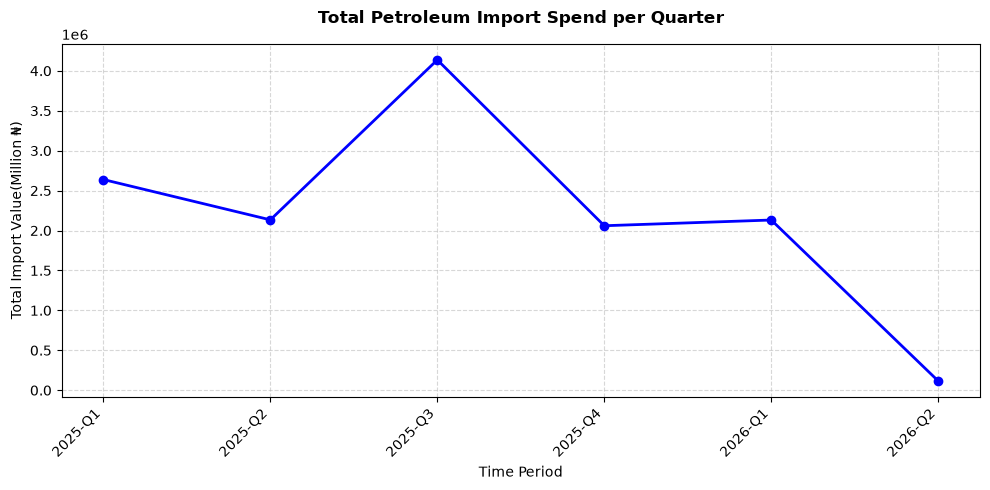

In [87]:
### Visulization
# Import value per quater

# Group data by Year and Quarter to get total spend per quarter

quarterly_imports = ranked_market_share.groupby(['Year', 'Quarter'])['Import Value(Million Naira)'].sum().reset_index()
quarterly_imports['Time_Period'] = quarterly_imports['Year'].astype(str) + '-' + quarterly_imports['Quarter'].astype(str)

# Build the chart
fig, axes = plt.subplots(figsize=(10, 5))
axes.plot(quarterly_imports['Time_Period'], quarterly_imports['Import Value(Million Naira)'], marker='o', color='b', linewidth=2)

# Titles and labels
axes.set_title('Total Petroleum Import Spend per Quarter', fontsize=12, fontweight='bold', pad=15)
axes.set_xlabel('Time Period', fontsize=10)
axes.set_ylabel('Total Import Value(Million ₦)', fontsize=10)
plt.xticks(rotation= 45, ha='right')
axes.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

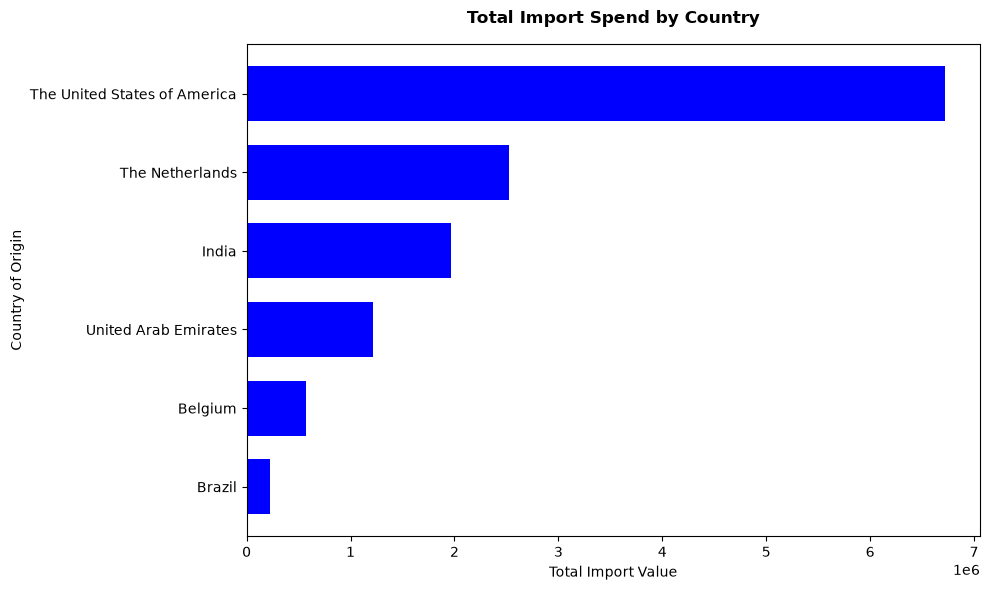

In [88]:
## Total imports from partner countries

# Group data by country and sum their total spend
country_sales = ranked_market_share.groupby('Country of Origin')['Import Value(Million Naira)'].sum().reset_index()

# Sort and take the top 10 countries
country_sales = country_sales.sort_values(by='Import Value(Million Naira)', ascending= False)

# Build the chart
fig, axes = plt.subplots(figsize=(10, 6))
axes.barh(country_sales['Country of Origin'], country_sales['Import Value(Million Naira)'], color='b', height = 0.7)

# 3. Titles and labels
axes.set_title('Total Import Spend by Country', fontsize=12, fontweight='bold', pad=15)
axes.set_xlabel('Total Import Value', fontsize=10)
axes.set_ylabel('Country of Origin', fontsize=10)
axes.invert_yaxis()   # largest at the top

plt.tight_layout()
plt.show()



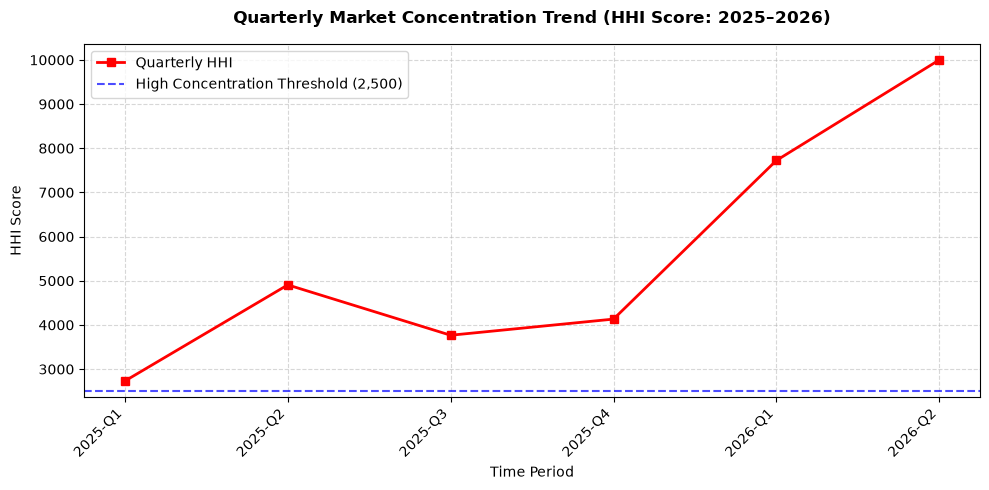

In [89]:
## Quarterly Market Concentration Trend (HHI Score)

# Extract unique quarter HHI scores
hhi_trend = hhi[['Year', 'Quarter', 'HHI_Score']].drop_duplicates().reset_index(drop=True)
hhi_trend['Time_Period'] = hhi_trend['Year'].astype(str) + '-' + hhi_trend['Quarter'].astype(str)

# Build the figure
fig, axes = plt.subplots(figsize=(10, 5))
axes.plot(hhi_trend['Time_Period'], hhi_trend['HHI_Score'], marker='s', color='r', linewidth=2.0, markersize=6, label='Quarterly HHI')

# Format titles, labels, and grid
axes.set_title('Quarterly Market Concentration Trend (HHI Score: 2025–2026)', fontsize=12, fontweight='bold', pad=15)
axes.set_xlabel('Time Period', fontsize=10)
axes.set_ylabel('HHI Score', fontsize=10)
plt.xticks(rotation=45, ha='right')
axes.grid(True, linestyle='--', alpha=0.5)

# Add a reference threshold line for high concentration (2,500)
axes.axhline(2500, color='b', linestyle='--', alpha=0.7, label='High Concentration Threshold (2,500)')
axes.legend(frameon=True)

plt.tight_layout()
plt.show()



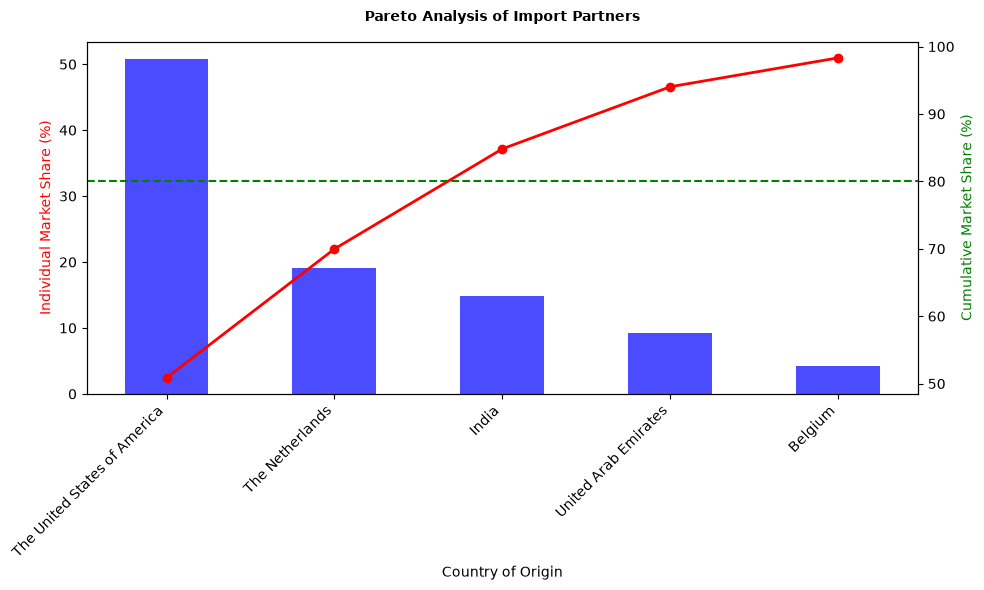

In [90]:


# Filter data for the full year of 2025 and group by country
year= ranked_market_share.groupby('Country of Origin')['Import Value(Million Naira)'].sum().reset_index()

# Calculate Market Share (%) and sort descending
total_import = year['Import Value(Million Naira)'].sum()
year['Market Share (%)'] = (year['Import Value(Million Naira)'] / total_import) * 100
year = year.sort_values(by='Market Share (%)', ascending=False).reset_index(drop=True)

# Calculate Cumulative Market Share (%)
year['Cumulative Market Share (%)'] = year['Market Share (%)'].cumsum()

# Take the top 8 countries for a clean visual
subset = year.head().copy()

# Build the figure with dual axes
fig, ax1 = plt.subplots(figsize=(10, 6))

# Bar chart for individual market share (Left Y-Axis)
ax1.bar(subset['Country of Origin'], subset['Market Share (%)'], color='b', alpha=0.7, label='Market Share (%)', width = 0.5)
ax1.set_xlabel('Country of Origin', fontsize=10)
ax1.set_ylabel('Individual Market Share (%)', fontsize=10, color = 'r')
plt.xticks(rotation=45, ha='right')

# Line chart for cumulative market share (Right Y-Axis)
ax2 = ax1.twinx()
ax2.plot(subset['Country of Origin'], subset['Cumulative Market Share (%)'], color='r', marker='o', linewidth=2.0, label='Cumulative Share (%)')
ax2.set_ylabel('Cumulative Market Share (%)', fontsize=10, color='g')

# Add the 80% threshold line
ax2.axhline(80, color='green', linestyle='--', linewidth=1.5, label='80% Threshold')

# Titles and layout
plt.title('Pareto Analysis of Import Partners', fontsize=10, fontweight='bold', pad=15)


plt.tight_layout()
plt.show()

## Analysis of African Country Import

In [94]:
# convert to title case and strip extra whitespace

africa_petroleum_data['Country of Origin']= africa_petroleum_data['Country of Origin'].str.title().str.strip()

africa_petroleum_data['Products Description']= africa_petroleum_data['Products Description'].str.replace('Petroleum oils and oils obtained from bituminous minerals, crude.','Petroleum and Bituminous oils')

africa_petroleum_data

,Code,Country of Origin,HS Code,Products Description,Import Value(Million ₦),Quarter,Year
0,AO,Angola,2709000000,Petroleum and Bituminous oils,223582.181874,Q1,2025
1,TG,Togo,2710125000,"Motor spirit, ordinary",89179.185720,Q1,2025
2,TG,Togo,2710192100,Gas oil,23150.207548,Q1,2025
3,TG,Togo,2710123000,Aviation spirit,17514.003090,Q1,2025
4,DZ,Algeria,2709000000,Petroleum and Bituminous oils,122366.703583,Q1,2025
5,EG,Egypt,2710192400,Heavy fuel oil I,9273.191303,Q1,2025
6,TG,Togo,2710125000,"Motor spirit, ordinary",208763.564572,Q2,2025
7,CI,Ivory Coast,2713200000,Petroleum bitumen,14426.569561,Q2,2025
8,GQ,Equatorial Guinea,2709000000,Petroleum and Bituminous oils,97170.664232,Q2,2025
9,GH,Ghana,2709000000,Petroleum and Bituminous oils,96268.797815,Q3,2025


In [95]:
## Determine individual spend around Africa

africa_country_spend = africa_petroleum_data.groupby(['Year', 'Quarter', 'Country of Origin'] , as_index = False)['Import Value(Million ₦)'].sum()
africa_country_spend

,Year,Quarter,Country of Origin,Import Value(Million ₦)
0,2025,Q1,Algeria,122366.703583
1,2025,Q1,Angola,223582.181874
2,2025,Q1,Egypt,9273.191303
3,2025,Q1,Togo,129843.396358
4,2025,Q2,Equatorial Guinea,97170.664232
5,2025,Q2,Ivory Coast,14426.569561
6,2025,Q2,Togo,208763.564572
7,2025,Q3,Ghana,96268.797815
8,2025,Q3,Ivory Coast,22683.993726
9,2025,Q4,Ghana,92672.099109


In [96]:
## Africa Total Quaterly spend

africa_quarterly_spend = africa_petroleum_data.groupby(['Year', 'Quarter'], as_index = False)['Import Value(Million ₦)'].sum()

africa_quarterly_spend = africa_quarterly_spend.rename(columns={'Import Value(Million ₦)': 'Africa Quarterly Spend'})

africa_quarterly_spend

,Year,Quarter,Africa Quarterly Spend
0,2025,Q1,485065.473118
1,2025,Q2,320360.798365
2,2025,Q3,118952.791540
3,2025,Q4,177359.404299
4,2026,Q1,144187.758969
5,2026,Q2,628886.281021


In [97]:
## Merge Africa total and quaterly spend

africa_spend = pd.merge(africa_country_spend, africa_quarterly_spend, on = ['Year', 'Quarter'])
africa_spend

,Year,Quarter,Country of Origin,Import Value(Million ₦),Africa Quarterly Spend
0,2025,Q1,Algeria,122366.703583,485065.473118
1,2025,Q1,Angola,223582.181874,485065.473118
2,2025,Q1,Egypt,9273.191303,485065.473118
3,2025,Q1,Togo,129843.396358,485065.473118
4,2025,Q2,Equatorial Guinea,97170.664232,320360.798365
5,2025,Q2,Ivory Coast,14426.569561,320360.798365
6,2025,Q2,Togo,208763.564572,320360.798365
7,2025,Q3,Ghana,96268.797815,118952.791540
8,2025,Q3,Ivory Coast,22683.993726,118952.791540
9,2025,Q4,Ghana,92672.099109,177359.404299


In [98]:
## Obtain the percentage share

africa_spend['Market Share (%)'] = (africa_spend['Import Value(Million ₦)'] / africa_spend['Africa Quarterly Spend']) * 100
africa_spend['Market Share (%)'] = africa_spend['Market Share (%)'].round(2)
africa_spend

,Year,Quarter,Country of Origin,Import Value(Million ₦),Africa Quarterly Spend,Market Share (%)
0,2025,Q1,Algeria,122366.703583,485065.473118,25.23
1,2025,Q1,Angola,223582.181874,485065.473118,46.09
2,2025,Q1,Egypt,9273.191303,485065.473118,1.91
3,2025,Q1,Togo,129843.396358,485065.473118,26.77
4,2025,Q2,Equatorial Guinea,97170.664232,320360.798365,30.33
5,2025,Q2,Ivory Coast,14426.569561,320360.798365,4.50
6,2025,Q2,Togo,208763.564572,320360.798365,65.17
7,2025,Q3,Ghana,96268.797815,118952.791540,80.93
8,2025,Q3,Ivory Coast,22683.993726,118952.791540,19.07
9,2025,Q4,Ghana,92672.099109,177359.404299,52.25


In [99]:
## Ranking the countries by percentage share

africa_ranked_share = africa_spend.sort_values(by=['Year', 'Quarter', 'Market Share (%)'], ascending=[True, True, False]).reset_index(drop=True)

africa_ranked_share ['Rank'] = africa_ranked_share.groupby(['Year', 'Quarter'])['Market Share (%)'].rank(ascending=False, method='min').astype(int)

africa_ranked_share 

,Year,Quarter,Country of Origin,Import Value(Million ₦),Africa Quarterly Spend,Market Share (%),Rank
0,2025,Q1,Angola,223582.181874,485065.473118,46.09,1
1,2025,Q1,Togo,129843.396358,485065.473118,26.77,2
2,2025,Q1,Algeria,122366.703583,485065.473118,25.23,3
3,2025,Q1,Egypt,9273.191303,485065.473118,1.91,4
4,2025,Q2,Togo,208763.564572,320360.798365,65.17,1
5,2025,Q2,Equatorial Guinea,97170.664232,320360.798365,30.33,2
6,2025,Q2,Ivory Coast,14426.569561,320360.798365,4.50,3
7,2025,Q3,Ghana,96268.797815,118952.791540,80.93,1
8,2025,Q3,Ivory Coast,22683.993726,118952.791540,19.07,2
9,2025,Q4,Ghana,92672.099109,177359.404299,52.25,1


In [100]:
# Calculate cumulative sum of market share within each quarter (from highest to lowest)

africa_ranked_share['Cumulative Market Share (%)'] = africa_ranked_share.groupby(['Year', 'Quarter'])['Market Share (%)'].cumsum()

display(africa_ranked_share)

,Year,Quarter,Country of Origin,Import Value(Million ₦),Africa Quarterly Spend,Market Share (%),Rank,Cumulative Market Share (%)
0,2025,Q1,Angola,223582.181874,485065.473118,46.09,1,46.09
1,2025,Q1,Togo,129843.396358,485065.473118,26.77,2,72.86
2,2025,Q1,Algeria,122366.703583,485065.473118,25.23,3,98.09
3,2025,Q1,Egypt,9273.191303,485065.473118,1.91,4,100.00
4,2025,Q2,Togo,208763.564572,320360.798365,65.17,1,65.17
5,2025,Q2,Equatorial Guinea,97170.664232,320360.798365,30.33,2,95.50
6,2025,Q2,Ivory Coast,14426.569561,320360.798365,4.50,3,100.00
7,2025,Q3,Ghana,96268.797815,118952.791540,80.93,1,80.93
8,2025,Q3,Ivory Coast,22683.993726,118952.791540,19.07,2,100.00
9,2025,Q4,Ghana,92672.099109,177359.404299,52.25,1,52.25


In [101]:
### Calculate the HHI market concentration

hhi_africa = africa_ranked_share.groupby(['Year', 'Quarter'], as_index=False).agg(HHI_Score=('Market Share (%)', lambda x: (x**2).sum()))

display(hhi_africa)

,Year,Quarter,HHI_Score
0,2025,Q1,3481.1220
1,2025,Q2,5187.2878
2,2025,Q3,6913.3298
3,2025,Q4,5010.1250
4,2026,Q1,10000.0000
5,2026,Q2,3322.1846


In [102]:
## Total World Import and Africa Import

total_spend = ranked_market_share['Import Value(Million Naira)'].sum()
print(f'{total_spend.round(3)} Million naira')


13216194.908 Million naira


In [103]:
total_africa_spend = africa_ranked_share['Import Value(Million ₦)'].sum()
print(f'{total_africa_spend.round(3)} naira')

1874812.507 naira


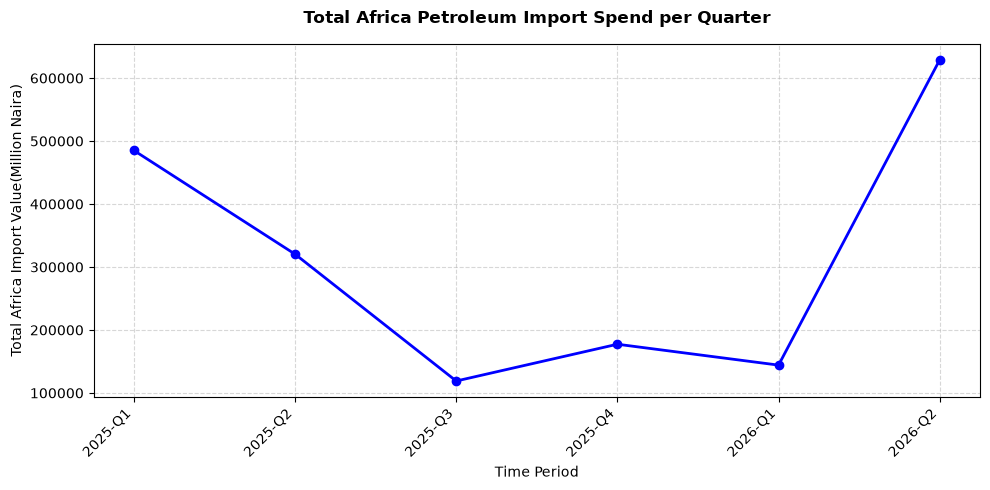

In [104]:
## Visulization
# Import value per quater

# Group data by Year and Quarter to get total spend per quarter

africa_quarterly_spends = africa_ranked_share.groupby(['Year', 'Quarter'])['Import Value(Million ₦)'].sum().reset_index()
africa_quarterly_spends['Time_Period'] = africa_quarterly_spends['Year'].astype(str) + '-' + africa_quarterly_spends['Quarter'].astype(str)

# Build the chart
fig, axes = plt.subplots(figsize=(10, 5))
axes.plot(africa_quarterly_spends['Time_Period'], africa_quarterly_spends['Import Value(Million ₦)'], marker='o', color='b', linewidth=2)

# Titles and labels
axes.set_title('Total Africa Petroleum Import Spend per Quarter', fontsize=12, fontweight='bold', pad=15)
axes.set_xlabel('Time Period', fontsize=10)
axes.set_ylabel('Total Africa Import Value(Million Naira)', fontsize=10)
plt.xticks(rotation= 45, ha='right')
axes.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

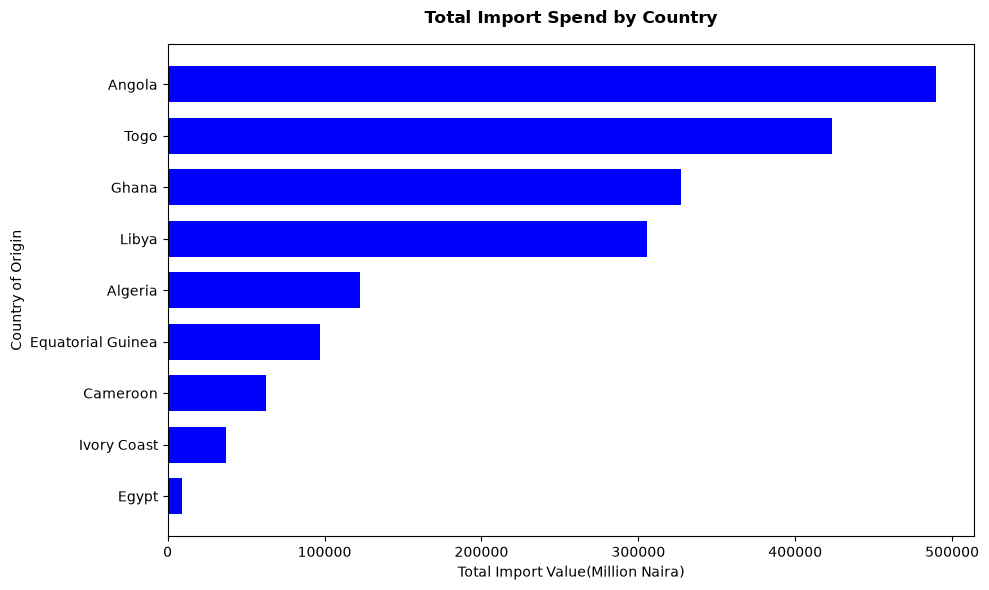

In [106]:
## Total imports from Africa partner countries

# Group data by country and sum their total spend
africa_country_sales = africa_ranked_share.groupby('Country of Origin')['Import Value(Million ₦)'].sum().reset_index()

# Sort and take the top 10 countries
africa_country_sales = africa_country_sales.sort_values(by='Import Value(Million ₦)', ascending= False)

# Build the chart
fig, axes = plt.subplots(figsize=(10, 6))
axes.barh(africa_country_sales['Country of Origin'], africa_country_sales['Import Value(Million ₦)'], color='b', height = 0.7)

# 3. Titles and labels
axes.set_title('Total Import Spend by Country', fontsize=12, fontweight='bold', pad=15)
axes.set_xlabel('Total Import Value(Million Naira)', fontsize=10)
axes.set_ylabel('Country of Origin', fontsize=10)
axes.invert_yaxis()   # largest at the top

plt.tight_layout()
plt.show()

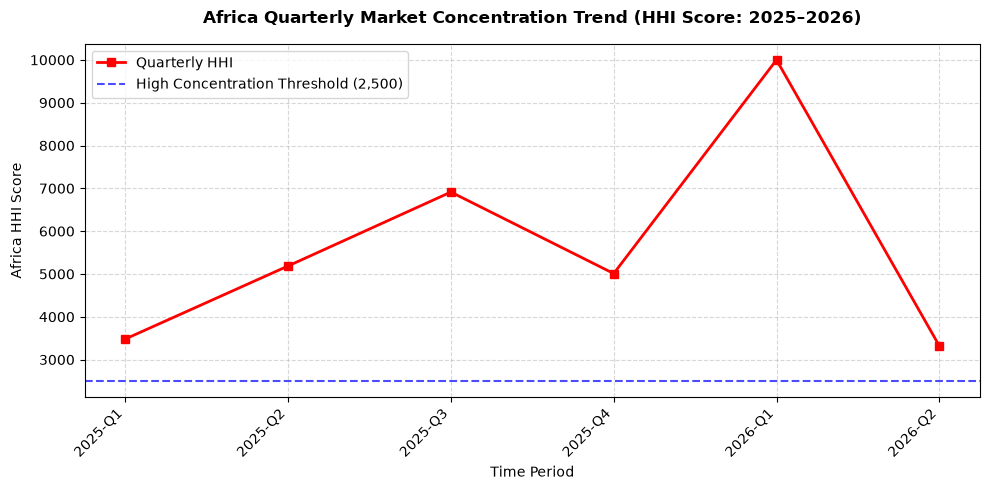

In [107]:
## Quarterly Afica Market Concentration Trend (HHI Score)

# Extract unique quarter HHI scores
hhi_trend = hhi_africa[['Year', 'Quarter', 'HHI_Score']].drop_duplicates().reset_index(drop=True)
hhi_trend['Time_Period'] = hhi_trend['Year'].astype(str) + '-' + hhi_trend['Quarter'].astype(str)

# Build the figure
fig, axes = plt.subplots(figsize=(10, 5))
axes.plot(hhi_trend['Time_Period'], hhi_trend['HHI_Score'], marker='s', color='r', linewidth=2.0, markersize=6, label='Quarterly HHI')

# Format titles, labels, and grid
axes.set_title('Africa Quarterly Market Concentration Trend (HHI Score: 2025–2026)', fontsize=12, fontweight='bold', pad=15)
axes.set_xlabel('Time Period', fontsize=10)
axes.set_ylabel('Africa HHI Score', fontsize=10)
plt.xticks(rotation=45, ha='right')
axes.grid(True, linestyle='--', alpha=0.5)

# Add a reference threshold line for high concentration (2,500)
axes.axhline(2500, color='b', linestyle='--', alpha=0.7, label='High Concentration Threshold (2,500)')
axes.legend(frameon=True)

plt.tight_layout()
plt.show()

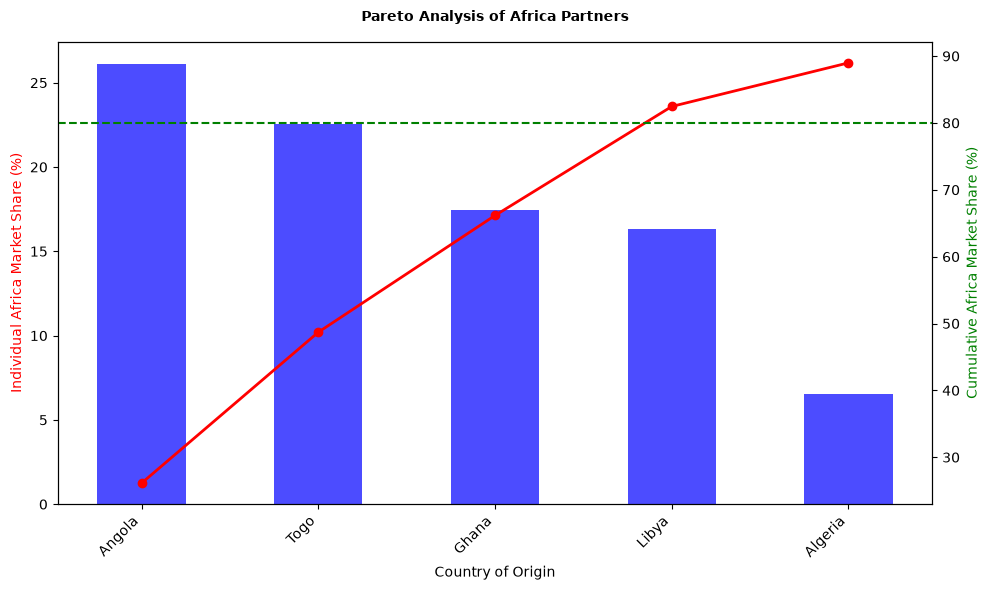

In [108]:
# Filter data for the full year of 2025 and group by country
year= africa_ranked_share.groupby('Country of Origin')['Import Value(Million ₦)'].sum().reset_index()

# Calculate Market Share (%) and sort descending
total_import = year['Import Value(Million ₦)'].sum()
year['Market Share (%)'] = (year['Import Value(Million ₦)'] / total_import) * 100
year = year.sort_values(by='Market Share (%)', ascending=False).reset_index(drop=True)

# Calculate Cumulative Market Share (%)
year['Cumulative Market Share (%)'] = year['Market Share (%)'].cumsum()

# Take the top 8 countries for a clean visual
subset = year.head().copy()

# Build the figure with dual axes
fig, ax1 = plt.subplots(figsize=(10, 6))

# Bar chart for individual market share (Left Y-Axis)
ax1.bar(subset['Country of Origin'], subset['Market Share (%)'], color='b', alpha=0.7, label='Market Share (%)', width = 0.5)
ax1.set_xlabel('Country of Origin', fontsize=10)
ax1.set_ylabel('Individual Africa Market Share (%)', fontsize=10, color = 'r')
plt.xticks(rotation=45, ha='right')

# Line chart for cumulative market share (Right Y-Axis)
ax2 = ax1.twinx()
ax2.plot(subset['Country of Origin'], subset['Cumulative Market Share (%)'], color='r', marker='o', linewidth=2.0, label='Cumulative Share (%)')
ax2.set_ylabel('Cumulative Africa Market Share (%)', fontsize=10, color='g')

# Add the 80% threshold line
ax2.axhline(80, color='green', linestyle='--', linewidth=1.5, label='80% Threshold')

# Titles and layout
plt.title('Pareto Analysis of Africa Partners', fontsize=10, fontweight='bold', pad=15)


plt.tight_layout()
plt.show()